<a href="https://colab.research.google.com/github/Prajwaln08/SQLSmith/blob/main/notebooks/11_SFT_Error_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SQLSmith — Notebook 11 | Paired SFT Error Analysis

**Milestone C · CPU only · Spider 1.0 full dev (1,034 questions)**

**Objective:** Determine exactly which questions improved/regressed after QLoRA SFT for **Qwen2.5-Coder 1.5B and 7B**, with frozen Notebook 10 predictions and the **same pinned augmented Spider evaluator**. This notebook does **not** train or generate SQL.

**Workflow:** verify artifact fingerprints → restore evaluator and test suites → re-score **each** model/question using official `eval_exec_match` → reproduce Notebook 10 aggregates → paired confusion tables and difficulty/database/SQL-feature breakdowns → export inspectable case lists and a prioritized Milestone C report.

**Interpretation:** Spike in an error category = association, not proof of root cause. SQL text similarity is **never** used to determine correctness. Spider dev is not an independent held-out test; avoid choosing a method by repeatedly optimizing against it.

## 1 — Install CPU dependencies
Run in a fresh **CPU** Google Colab session. No `transformers`, `torch`, or GPU allocation needed.

In [1]:
%pip install -q -U pandas numpy matplotlib scipy tqdm sqlglot huggingface_hub nltk

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.5 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.5.0 which is incompatible.
ibis-framework 9.5.0 requires sqlglot<25.21,>=23.4, but you have sqlglot 30.35.0 which is incompatible.


## 2 — Mount Drive and define immutable inputs
The five input datasets are **Notebook 10's four prediction CSVs and official comparison report**. No training outputs are changed. `OUT` is a new Milestone C folder.

In [2]:
from google.colab import drive
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import json, sys, os, csv, re, hashlib, zipfile, subprocess, sqlite3, time, math
import numpy as np
import pandas as pd
from IPython.display import display

if not Path('/content/drive/MyDrive').is_dir():
    drive.mount('/content/drive')
PROJECT = Path('/content/drive/MyDrive/Prajwal/Projects/SQLSmith')
B = PROJECT / 'results/milestone_B/official_eval'
BASE = PROJECT / 'results/full_spider'
OUT = PROJECT / 'results/milestone_C/error_analysis'
OUT.mkdir(parents=True, exist_ok=True)
MODEL_IDS = {
    '1.5b': 'Qwen/Qwen2.5-Coder-1.5B-Instruct',
    '7b': 'Qwen/Qwen2.5-Coder-7B-Instruct',
}
PRED_FILES = {
    ('1.5b','base'): BASE/'spider_1.5b_full_dev_predictions.csv',
    ('1.5b','sft'): B/'spider_sft_1.5b_full_dev_predictions.csv',
    ('7b','base'): BASE/'spider_7b_full_dev_predictions.csv',
    ('7b','sft'): B/'spider_sft_7b_full_dev_predictions.csv',
}
REPORT_PATH = B/'10_sft_official_comparison_report.json'
EXPECTED_DISPLAYED = {('1.5b','base'):0.425,('1.5b','sft'):0.594,
                      ('7b','base'):0.732,('7b','sft'):0.751}
EVALUATOR_COMMIT = 'e97acc546ecbee8fa27fa8dbf025ef61493a876c'
SUITE_SHA = '9ec24ea8debc6bd04abfe137b5f1a739b5a8836f32c0464e4dfc94eb7f41da96'
SPIDER_ARCHIVE_SHA = '00636695dabed6b5f4b8328a16b13e069a2f16591d5efcce57660669c85b121b'

def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(1024*1024), b''):h.update(block)
    return h.hexdigest()

assert all(p.is_file() for p in list(PRED_FILES.values())+[REPORT_PATH]), 'Missing Notebook 10 outputs'
report10=json.loads(REPORT_PATH.read_text(encoding='utf-8'))
assert report10['evaluator_commit']==EVALUATOR_COMMIT
assert report10['plug_value'] is False and report10['keep_distinct'] is False
assert report10['etype']=='exec'
for (model,variant),path in PRED_FILES.items():
    recorded=report10['prediction_csv_sha256'][f'{model}_{variant}']
    assert sha256_file(path)==recorded, f'Input changed since Notebook 10: {path}'
    print('VERIFIED',model,variant, path.name)
print('Official comparison report:',REPORT_PATH)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Mounted at /content/drive
VERIFIED 1.5b base spider_1.5b_full_dev_predictions.csv
VERIFIED 1.5b sft spider_sft_1.5b_full_dev_predictions.csv
VERIFIED 7b base spider_7b_full_dev_predictions.csv
VERIFIED 7b sft spider_sft_7b_full_dev_predictions.csv
Official comparison report: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/milestone_B/official_eval/10_sft_official_comparison_report.json


## 3 — Recover exact Spider dev metadata and align all four predictions
This deliberately duplicates Notebook 10's SHA and row-alignment safeguards.

In [3]:
from huggingface_hub import hf_hub_download
SPIDER = Path('/content/sqlsmith_data/spider_data')
ARCHIVE = hf_hub_download(repo_id='HAL-9001/spider-databases', repo_type='dataset', filename='spider_data.zip')
assert sha256_file(ARCHIVE)==SPIDER_ARCHIVE_SHA, 'Spider archive mismatch'
if not all((SPIDER/x).is_file() for x in ('dev.json','tables.json')):
    root=Path('/content/sqlsmith_data').resolve();root.mkdir(exist_ok=True,parents=True)
    with zipfile.ZipFile(ARCHIVE) as z:
        for entry in z.infolist():
            assert (root/entry.filename).resolve().is_relative_to(root), 'Unsafe ZIP path'
        z.extractall(root)
DEV = SPIDER/'dev.json'
TABLES = SPIDER/'tables.json'
assert sha256_file(DEV)==report10['spider_dev_sha256']
assert sha256_file(TABLES)==report10['spider_tables_sha256']
dev=json.loads(DEV.read_text(encoding='utf-8'))
schema_json={x['db_id']:x for x in json.loads(TABLES.read_text(encoding='utf-8'))}
assert len(dev)==1034 and len(set(x['db_id'] for x in dev))==20
FRAMES={}
for (model,variant),file in PRED_FILES.items():
    frame=pd.read_csv(file,keep_default_na=False)
    frame['index']=pd.to_numeric(frame['index'],errors='raise').astype(int)
    frame=frame.sort_values('index').reset_index(drop=True)
    assert len(frame)==1034 and frame['index'].tolist()==list(range(1,1035))
    for i,r in frame.iterrows():
        original=dev[i]
        assert r['db_id']==original['db_id'] and r['question']==original['question']
        assert ' '.join(str(r['gold_sql']).split())==' '.join(original['query'].split())
        assert r['model']==MODEL_IDS[model]
    FRAMES[(model,variant)]=frame
    print('ALIGNED',model,variant,len(frame))
print('PASS: four prediction sets identical question order and immutable source files')

spider_data.zip: reconstructing file:   0%|          |  0.00B /  206MB            

spider_data.zip: downloading bytes:           |  0.00B            

ALIGNED 1.5b base 1034
ALIGNED 1.5b sft 1034
ALIGNED 7b base 1034
ALIGNED 7b sft 1034
PASS: four prediction sets identical question order and immutable source files


## 4 — Restore the exact official evaluator and augmented test suites
Uses the **same pinned evaluator commit and SHA256 archive** as Notebooks 06 and 10. Per-question outcomes use its native `eval_exec_match` function, not a custom SQL equality heuristic.

In [4]:
import nltk
nltk.download('punkt',quiet=True)
nltk.download('punkt_tab',quiet=True)
EVAL_REPO=Path('/content/test-suite-sql-eval')
if not (EVAL_REPO/'.git').is_dir():
    subprocess.run(['git','clone','https://github.com/taoyds/test-suite-sql-eval.git',str(EVAL_REPO)],check=True)
subprocess.run(['git','-C',str(EVAL_REPO),'checkout','--detach',EVALUATOR_COMMIT],check=True)
assert subprocess.check_output(['git','-C',str(EVAL_REPO),'rev-parse','HEAD'],text=True).strip()==EVALUATOR_COMMIT
ZIP=PROJECT/'data/testsuitedatabases.zip'
if not ZIP.is_file(): ZIP=Path('/content/testsuitedatabases.zip')
assert ZIP.is_file(), 'Copy test-suite ZIP from Notebook 10 to SQLSmith/data/testsuitedatabases.zip'
assert zipfile.is_zipfile(ZIP) and sha256_file(ZIP)==SUITE_SHA
SUITES=Path('/content/sqlsmith_test_suites'); SUITES.mkdir(parents=True,exist_ok=True)
with zipfile.ZipFile(ZIP) as z:
    for entry in z.infolist():
        assert (SUITES.resolve()/entry.filename).resolve().is_relative_to(SUITES.resolve()), 'Unsafe ZIP path'
    z.extractall(SUITES)
required=set(row['db_id'] for row in dev)
roots=[]
for candidate in SUITES.rglob('*.sqlite'):
    if candidate.stem in required and candidate.parent.name==candidate.stem:
        root=candidate.parent.parent
        if all((root/d/f'{d}.sqlite').is_file() for d in required): roots.append(root)
assert roots, 'Cannot locate all 20 augmented Spider database folders'
SUITE_DB_ROOT=max(set(roots),key=lambda p:sum(len(list((p/d).glob('*.sqlite'))) for d in required))
assert report10['suite_zip_sha256']==sha256_file(ZIP)
sys.path.insert(0,str(EVAL_REPO))
from exec_eval import eval_exec_match
from evaluation import Evaluator, Schema, get_schema, get_sql
print('Pinned evaluator:',EVALUATOR_COMMIT)
print('Database root:',SUITE_DB_ROOT)
print('Augmented DB count:',sum(len(list((SUITE_DB_ROOT/d).glob('*.sqlite'))) for d in required))

Pinned evaluator: e97acc546ecbee8fa27fa8dbf025ef61493a876c
Database root: /content/sqlsmith_test_suites/database
Augmented DB count: 695


/content/test-suite-sql-eval/exec_eval.py:127: SyntaxWarning: invalid escape sequence '\s'
  "YEAR\s*\(\s*CURDATE\s*\(\s*\)\s*\)\s*", "2020", query, flags=re.IGNORECASE
/content/test-suite-sql-eval/parse.py:57: SyntaxWarning: invalid escape sequence '\d'
  float_nums = re.findall("[-+]?\d*\.\d+", query)
/content/test-suite-sql-eval/parse.py:62: SyntaxWarning: invalid escape sequence '\d'
  int_nums = [i.strip() for i in re.findall("[^tT]\d+", query)]
/content/test-suite-sql-eval/parse.py:70: SyntaxWarning: invalid escape sequence '\d'
  table = re.findall("[Tt]\d+\.", tok)
/content/test-suite-sql-eval/parse.py:206: SyntaxWarning: invalid escape sequence '\.'
  for table, col, val1, val2 in re.findall('(?:([^\.\s]*)\.)?([^\.\s]+) between ([^\s;]+) and ([^\s;]+)', query, re.IGNORECASE):


## 5 — Exact per-question official evaluation, with resumable checkpoint

**This cell performs the actual CPU work** (4 × 1,034 frozen predictions). It may take considerably longer than earlier sections. It appends one record after each completed evaluation and resumes safely after a Colab disconnect.

The official CLI calls `p_str.replace("value", "1")` before `eval_exec_match`. We reproduce **that exact behavior**, including `plug_value=False`, `keep_distinct=False`, and the augmented test-suite root. We also take difficulty labels from the pinned official evaluator's SQL parser. Any unexpected exception **stops the run** rather than silently scoring a sample as incorrect.

In [6]:

# Fix asyncio conflicts in Google Colab / Jupyter

%pip install -q nest_asyncio

import nest_asyncio
nest_asyncio.apply()

print("AsyncIO compatibility patch applied.")
print("Ready to run official Spider evaluation.")


AsyncIO compatibility patch applied.
Ready to run official Spider evaluation.


In [7]:
from tqdm.auto import tqdm

def one_line(value): return ' '.join(str(value).split())
CACHE=OUT/'11_per_question_official_checkpoint.jsonl'
input_signature={f'{m}_{v}':sha256_file(path) for (m,v),path in PRED_FILES.items()}
cache_meta={'evaluator_commit':EVALUATOR_COMMIT,'suite_zip_sha256':SUITE_SHA,
            'spider_dev_sha256':sha256_file(DEV),'prediction_sha256':input_signature,
            'plug_value':False,'keep_distinct':False}
META_FILE=OUT/'11_per_question_checkpoint_meta.json'
if META_FILE.is_file():
    assert json.loads(META_FILE.read_text(encoding='utf-8'))==cache_meta, 'Prior cache is from different inputs or evaluator. Archive it before starting a new study.'
else:
    assert not CACHE.is_file() or CACHE.stat().st_size==0, 'Found checkpoint with no provenance metadata; inspect manually.'
    META_FILE.write_text(json.dumps(cache_meta,indent=2),encoding='utf-8')
completed={}
if CACHE.is_file():
    for line in CACHE.read_text(encoding='utf-8').splitlines():
        if not line.strip():continue
        r=json.loads(line)
        key=(r['model'],r['variant'],int(r['index']))
        assert key not in completed, f'Duplicate cached evaluation: {key}'
        completed[key]=r
print('Resuming:',len(completed),'of',4*len(dev),'question/model outcomes already cached')

evaluator=Evaluator()
difficulty_cache={}
for i,item in enumerate(dev,1):
    db_path=SUITE_DB_ROOT/item['db_id']/(item['db_id']+'.sqlite')
    db_schema=Schema(get_schema(str(db_path)))
    difficulty_cache[i]=evaluator.eval_hardness(get_sql(db_schema,item['query']))

jobs=[(m,v,i) for m,v in [('1.5b','base'),('1.5b','sft'),('7b','base'),('7b','sft')] for i in range(1,1035)]
with CACHE.open('a',encoding='utf-8') as f:
    for model,variant,i in tqdm(jobs,desc='Official per-question scoring'):
        k=(model,variant,i)
        if k in completed:continue
        row=FRAMES[(model,variant)].iloc[i-1]
        item=dev[i-1]
        db_path=SUITE_DB_ROOT/item['db_id']/(item['db_id']+'.sqlite')
        pred=one_line(row['predicted_sql']).replace('value','1')
        gold=one_line(item['query'])
        try:
            correct=int(eval_exec_match(db=str(db_path),p_str=pred,g_str=gold,
                                        plug_value=False,keep_distinct=False,
                                        progress_bar_for_each_datapoint=False))
        except Exception as exc:
            raise RuntimeError(f'Official scoring failed for {k}; cached outcomes remain available') from exc
        assert correct in (0,1)
        result={'model':model,'variant':variant,'index':i,'db_id':item['db_id'],
                'difficulty':difficulty_cache[i],'correct':correct}
        f.write(json.dumps(result,ensure_ascii=False)+'\n')
        f.flush()
        completed[k]=result
print('Cached official decisions:',len(completed),'of',len(jobs))
assert len(completed)==len(jobs), 'Incomplete per-question scoring: rerun Section 5 to resume'

Resuming: 0 of 4136 question/model outcomes already cached


Official per-question scoring:   0%|          | 0/4136 [00:00<?, ?it/s]

Cached official decisions: 4136 of 4136


## 6 — Reconcile per-question labels against all four official Notebook 10 scores
**Hard stop** if per-question decisions disagree with previously reported aggregate scores. Notebook 10 displays 3-decimal values, so reconciliation uses the official rounded values.

In [8]:
decisions=pd.DataFrame(list(completed.values()))
assert len(decisions)==4*1034
assert not decisions.duplicated(['model','variant','index']).any()
recon=[]
for (m,v),expected in EXPECTED_DISPLAYED.items():
    subset=decisions[(decisions.model==m)&(decisions.variant==v)]
    observed=int(subset.correct.sum())/1034
    assert abs(observed-expected)<0.0006, (
        f'{m}/{v} per-question score {observed:.6f} mismatches Notebook 10 {expected:.3f}; '
        'do not interpret regressions until evaluator inputs are reconciled.')
    recon.append({'model':m,'variant':v,'correct':int(subset.correct.sum()),
                  'total':1034,'recomputed':observed,'notebook10_rounded':expected})
recon_df=pd.DataFrame(recon)
display(recon_df)
recon_df.to_csv(OUT/'11_score_reconciliation.csv',index=False)
print('PASS: all 4 exact per-question outcomes reconcile with Notebook 10')

,model,variant,correct,total,recomputed,notebook10_rounded
0,1.5b,base,439,1034,0.424565,0.425
1,1.5b,sft,614,1034,0.593810,0.594
2,7b,base,757,1034,0.732108,0.732
3,7b,sft,777,1034,0.751451,0.751


PASS: all 4 exact per-question outcomes reconcile with Notebook 10


## 7 — Create aligned question-level matrix and paired SFT outcomes
For each model, partition the 1,034 questions into **fixed correct / regressed / still correct / still wrong**. Compare also how 1.5B SFT performs on cases where 7B SFT succeeds or fails.

In [9]:
outcome=decisions.pivot(index='index',columns=['model','variant'],values='correct')
expected_cols=[('1.5b','base'),('1.5b','sft'),('7b','base'),('7b','sft')]
assert all(c in outcome.columns for c in expected_cols)
Q=pd.DataFrame({'index':range(1,1035),'db_id':[x['db_id'] for x in dev],
                'question':[x['question'] for x in dev],
                'gold_sql':[x['query'] for x in dev],
                'difficulty':[difficulty_cache[i] for i in range(1,1035)]})
for (m,v) in expected_cols:
    Q[f'{m}_{v}_correct']=outcome[(m,v)].to_numpy().astype(int)
    predictions=FRAMES[(m,v)]['predicted_sql'].tolist()
    Q[f'{m}_{v}_sql']=predictions

def change_type(base,sft):
    return ('fixed_by_sft' if base==0 and sft==1 else
            'regressed_after_sft' if base==1 and sft==0 else
            'correct_both' if base==1 else 'wrong_both')
for m in ('1.5b','7b'):
    Q[f'{m}_change']=[change_type(a,b) for a,b in zip(Q[f'{m}_base_correct'],Q[f'{m}_sft_correct'])]
    counts=Q[f'{m}_change'].value_counts()
    assert counts.sum()==1034
    print(m, counts.to_dict())
Q['sft_7b_only_correct']=(Q['7b_sft_correct']==1)&(Q['1.5b_sft_correct']==0)
Q['sft_1p5b_only_correct']=(Q['1.5b_sft_correct']==1)&(Q['7b_sft_correct']==0)
Q.to_csv(OUT/'11_all_questions_paired.csv',index=False)
print('Question-level table:',OUT/'11_all_questions_paired.csv')

1.5b {'correct_both': 377, 'wrong_both': 358, 'fixed_by_sft': 237, 'regressed_after_sft': 62}
7b {'correct_both': 694, 'wrong_both': 194, 'fixed_by_sft': 83, 'regressed_after_sft': 63}
Question-level table: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/milestone_C/error_analysis/11_all_questions_paired.csv


## 8 — Quantify paired changes (McNemar exact and database-cluster bootstrap)

- **McNemar exact p**: descriptive paired comparison conditional on the discordant questions; not a separate-test-set validation.
- **Bootstrap interval**: resample the 20 **database IDs** (not individual rows) to reflect cross-database heterogeneity. These uncertainty summaries are exploratory because the development benchmark has already informed the research program.

In [10]:
from scipy.stats import binomtest
rng=np.random.default_rng(42)
dbs=sorted(Q.db_id.unique()); assert len(dbs)==20
paired=[]
for m in ('1.5b','7b'):
    b=Q[f'{m}_base_correct'];s=Q[f'{m}_sft_correct']
    fixed=int(((b==0)&(s==1)).sum())
    regressed=int(((b==1)&(s==0)).sum())
    net=fixed-regressed
    discordant=fixed+regressed
    p_exact=float(binomtest(min(fixed,regressed),n=discordant,p=.5).pvalue) if discordant else 1.0
    group={d:Q.loc[Q.db_id==d,[f'{m}_base_correct',f'{m}_sft_correct']].to_numpy() for d in dbs}
    boot=[]
    for _ in range(3000):
        sampled=rng.choice(dbs,size=len(dbs),replace=True)
        arr=np.concatenate([group[d] for d in sampled],axis=0)
        boot.append(100*(arr[:,1]-arr[:,0]).mean())
    paired.append({'model':m,'fixed_by_sft':fixed,'regressed_after_sft':regressed,
                   'net_correct_gain':net,'delta_pp_unrounded':100*net/1034,
                   'exact_mcnemar_p_exploratory':p_exact,
                   'cluster_bootstrap_95_low_pp':float(np.percentile(boot,2.5)),
                   'cluster_bootstrap_95_high_pp':float(np.percentile(boot,97.5))})
paired_df=pd.DataFrame(paired)
display(paired_df)
paired_df.to_csv(OUT/'11_paired_change_summary.csv',index=False)

,model,fixed_by_sft,regressed_after_sft,net_correct_gain,delta_pp_unrounded,exact_mcnemar_p_exploratory,cluster_bootstrap_95_low_pp,cluster_bootstrap_95_high_pp
0,1.5b,237,62,175,16.924565,2.881787e-25,12.489541,22.289918
1,7b,83,63,20,1.934236,1.155397e-01,-0.890911,4.940860


## 9 — Spider official difficulty and database-level breakdown
Difficulty labels are obtained from gold SQL using the **pinned official SQL parser**, not a keyword heuristic.

In [11]:
diff_rows=[]
for m in ('1.5b','7b'):
    for difficulty,g in Q.groupby('difficulty'):
        n=len(g); b=g[f'{m}_base_correct'].mean();s=g[f'{m}_sft_correct'].mean()
        diff_rows.append({'model':m,'difficulty':difficulty,'n':n,
                          'base_accuracy':b,'sft_accuracy':s,'delta_pp':100*(s-b),
                          'fixed':int((g[f'{m}_change']=='fixed_by_sft').sum()),
                          'regressed':int((g[f'{m}_change']=='regressed_after_sft').sum())})
diff_df=pd.DataFrame(diff_rows).sort_values(['model','difficulty'])
db_rows=[]
for m in ('1.5b','7b'):
    for db,g in Q.groupby('db_id'):
        b=g[f'{m}_base_correct'].mean();s=g[f'{m}_sft_correct'].mean()
        db_rows.append({'model':m,'db_id':db,'n':len(g),'base_accuracy':b,
                        'sft_accuracy':s,'delta_pp':100*(s-b),
                        'fixed':int((g[f'{m}_change']=='fixed_by_sft').sum()),
                        'regressed':int((g[f'{m}_change']=='regressed_after_sft').sum())})
db_df=pd.DataFrame(db_rows).sort_values(['model','delta_pp'])
display(diff_df)
display(db_df.groupby('model').head(5))
diff_df.to_csv(OUT/'11_by_official_difficulty.csv',index=False)
db_df.to_csv(OUT/'11_by_database.csv',index=False)

,model,difficulty,n,base_accuracy,sft_accuracy,delta_pp,fixed,regressed
0,1.5b,easy,248,0.653226,0.830645,17.741935,51,7
1,1.5b,extra,166,0.301205,0.367470,6.626506,22,11
2,1.5b,hard,174,0.258621,0.425287,16.666667,44,15
3,1.5b,medium,446,0.408072,0.612108,20.403587,120,29
4,7b,easy,248,0.883065,0.895161,1.209677,11,8
5,7b,extra,166,0.457831,0.506024,4.819277,23,15
6,7b,hard,174,0.655172,0.643678,-1.149425,15,17
7,7b,medium,446,0.780269,0.804933,2.466368,34,23


,model,db_id,n,base_accuracy,sft_accuracy,delta_pp,fixed,regressed
10,1.5b,orchestra,40,0.675000,0.650000,-2.500000,2,3
13,1.5b,real_estate_properties,4,0.500000,0.500000,0.000000,0,0
1,1.5b,car_1,92,0.358696,0.413043,5.434783,14,9
5,1.5b,dog_kennels,82,0.426829,0.500000,7.317073,15,9
18,1.5b,world_1,120,0.258333,0.366667,10.833333,18,5
33,7b,real_estate_properties,4,0.500000,0.250000,-25.000000,0,1
31,7b,pets_1,42,0.833333,0.714286,-11.904762,3,8
23,7b,course_teach,30,0.766667,0.700000,-6.666667,3,5
29,7b,network_1,56,0.875000,0.839286,-3.571429,0,2
34,7b,singer,30,0.966667,0.933333,-3.333333,0,1


## 10 — Multi-label gold SQL feature analysis
Uses **gold SQL**, not predictions, to associate difficulty with SQL structures. Tags overlap: do **not** sum their counts. Categories represent **diagnostic slices**, not causal error explanations.

In [12]:
import sqlglot
from sqlglot import exp

def gold_sql_features(sql):
    try:
        tree=sqlglot.parse_one(sql,read='sqlite')
        if tree is None: raise ValueError('No SQL AST')
        table_names={x.name.lower() for x in tree.find_all(exp.Table)}
        return {
            'multi_table':len(table_names)>1,
            'explicit_join':any(True for _ in tree.find_all(exp.Join)),
            'aggregation':any(isinstance(x,exp.AggFunc) for x in tree.walk()),
            'group_by':any(True for _ in tree.find_all(exp.Group)),
            'having':any(True for _ in tree.find_all(exp.Having)),
            'order_by':any(True for _ in tree.find_all(exp.Order)),
            'limit':any(True for _ in tree.find_all(exp.Limit)),
            'distinct':any(True for _ in tree.find_all(exp.Distinct)),
            'set_operation':any(isinstance(x,(exp.Union,exp.Intersect,exp.Except)) for x in tree.walk()),
            'nested_select':sum(isinstance(x,exp.Select) for x in tree.walk())>1,
        }
    except Exception:
        return {k:False for k in (
            'multi_table','explicit_join','aggregation','group_by','having',
            'order_by','limit','distinct','set_operation','nested_select')}

features=pd.DataFrame([gold_sql_features(x) for x in Q.gold_sql]).astype(bool)
assert len(features)==1034
for col in features.columns:Q['gold_'+col]=features[col].to_numpy()
feature_rows=[]
for m in ('1.5b','7b'):
    for feature in features.columns:
        g=Q[Q['gold_'+feature]]
        if len(g)==0:continue
        b=g[f'{m}_base_correct'].mean();s=g[f'{m}_sft_correct'].mean()
        feature_rows.append({'model':m,'feature':feature,'n':len(g),
                             'baseline_accuracy':b,'sft_accuracy':s,'delta_pp':100*(s-b),
                             'sft_wrong_count':int((g[f'{m}_sft_correct']==0).sum()),
                             'regressed':int((g[f'{m}_change']=='regressed_after_sft').sum())})
feature_df=pd.DataFrame(feature_rows).sort_values(['model','sft_wrong_count'],ascending=[True,False])
display(feature_df)
feature_df.to_csv(OUT/'11_gold_sql_feature_breakdown.csv',index=False)

,model,feature,n,baseline_accuracy,sft_accuracy,delta_pp,sft_wrong_count,regressed
0,1.5b,multi_table,459,0.324619,0.418301,9.368192,267,45
1,1.5b,explicit_join,408,0.306373,0.394608,8.823529,247,37
2,1.5b,aggregation,551,0.517241,0.626134,10.889292,206,35
3,1.5b,group_by,277,0.440433,0.570397,12.996390,119,22
5,1.5b,order_by,237,0.413502,0.510549,9.704641,116,19
6,1.5b,limit,189,0.375661,0.449735,7.407407,104,17
9,1.5b,nested_select,159,0.194969,0.396226,20.125786,96,10
8,1.5b,set_operation,80,0.100000,0.375000,27.500000,50,2
7,1.5b,distinct,87,0.459770,0.517241,5.747126,42,3
4,1.5b,having,79,0.329114,0.506329,17.721519,39,5


## 11 — Failure triage and inspectable priority case lists
Flags include empty generation, SQLite compile/grounding errors, and common SQL-structure mismatches. They are **heuristic diagnostics only**; `official_correct` comes exclusively from the official augmented scorer.

SQLite explain-checks are limited to **read-only candidate SELECT/WITH queries** on the original Spider DB, never an attached production database. We never run generated queries as SQL in this section.

In [13]:
# This cell uses SQLite EXPLAIN only on public Spider files, in read-only mode.
# SQL validation error strings can be useful but are NOT themselves official correctness labels.

def sqlite_compile_error(db_id,sql):
    sql=one_line(sql)
    if not sql:return 'empty_sql'
    try:
        parsed=sqlglot.parse_one(sql,read='sqlite')
    except Exception:return 'parse_failure'
    if not isinstance(parsed,(exp.Select,exp.Union,exp.Intersect,exp.Except)):
        return 'not_select_query'
    if ';' in sql.rstrip(';'):return 'multiple_statements'
    db=SPIDER/'database'/db_id/(db_id+'.sqlite')
    if not db.is_file():return 'original_sqlite_missing'
    try:
        con=sqlite3.connect(db.resolve().as_uri()+'?mode=ro',uri=True,timeout=2)
        try:
            con.execute('EXPLAIN QUERY PLAN '+sql)
            return 'compiles'
        finally:con.close()
    except sqlite3.Error as ex:
        msg=str(ex).lower()
        for marker in ('no such column','no such table','ambiguous column name','syntax error',
                       'misuse of aggregate','no such function','wrong number of arguments'):
            if marker in msg:return marker.replace(' ','_')
        return 'sqlite_compile_other'

rows=[]
for m in ('1.5b','7b'):
    focus=Q[(Q[f'{m}_sft_correct']==0) | (Q[f'{m}_change']=='fixed_by_sft')]
    for _,r in focus.iterrows():
        err=sqlite_compile_error(r['db_id'],r[f'{m}_sft_sql']) if r[f'{m}_sft_correct']==0 else 'not_applicable_correct'
        rows.append({'model':m,'index':int(r['index']),'db_id':r['db_id'],
                     'difficulty':r['difficulty'],'change':r[f'{m}_change'],
                     'official_sft_correct':int(r[f'{m}_sft_correct']),
                     'compile_diagnostic':err,
                     'question':r['question'],'gold_sql':r['gold_sql'],
                     'baseline_sql':r[f'{m}_base_sql'],'sft_sql':r[f'{m}_sft_sql']})
triage=pd.DataFrame(rows)
triage.to_csv(OUT/'11_failure_triage.csv',index=False)
priority_order={'regressed_after_sft':0,'wrong_both':1,'fixed_by_sft':2,'correct_both':3}
priority=triage.assign(priority_rank=triage.change.map(priority_order))
priority=priority.sort_values(['model','priority_rank','difficulty','db_id','index'])
priority.to_csv(OUT/'11_manual_review_queue.csv',index=False)
print('Triage statuses (diagnostic, not exact failure causes):')
display(triage.groupby(['model','compile_diagnostic']).size().reset_index(name='n').sort_values(['model','n'],ascending=[True,False]).head(25))
print('Inspect first 30 cases:')
display(priority[['model','index','db_id','difficulty','change','compile_diagnostic','question']].head(30))

Triage statuses (diagnostic, not exact failure causes):


,model,compile_diagnostic,n
1,1.5b,compiles,258
5,1.5b,not_applicable_correct,237
3,1.5b,no_such_column,141
4,1.5b,no_such_table,17
6,1.5b,sqlite_compile_other,2
0,1.5b,ambiguous_column_name,1
2,1.5b,misuse_of_aggregate,1
7,7b,compiles,211
10,7b,not_applicable_correct,83
8,7b,no_such_column,43


Inspect first 30 cases:


,model,index,db_id,difficulty,change,compile_diagnostic,question
315,1.5b,496,battle_death,easy,regressed_after_sft,no_such_column,What is the average number of injuries caused ...
4,1.5b,10,concert_singer,easy,regressed_after_sft,compiles,What are the different countries with singers...
264,1.5b,414,museum_visit,easy,regressed_after_sft,compiles,What is the average age of the visitors whose ...
542,1.5b,829,orchestra,easy,regressed_after_sft,no_such_column,What are the record companies of orchestras in...
355,1.5b,560,student_transcripts_tracking,easy,regressed_after_sft,compiles,Whose permanent address is different from his ...
450,1.5b,706,world_1,easy,regressed_after_sft,compiles,How many countries have governments that are r...
467,1.5b,729,world_1,easy,regressed_after_sft,compiles,How many people live in Gelderland district?
204,1.5b,312,cre_Doc_Template_Mgt,extra,regressed_after_sft,compiles,What is the id and type code for the template ...
217,1.5b,344,cre_Doc_Template_Mgt,extra,regressed_after_sft,compiles,Which template type code is used by most numbe...
236,1.5b,375,cre_Doc_Template_Mgt,extra,regressed_after_sft,no_such_column,Return the id and name of the document with th...


## 12 — Plot paired gains and breakdowns
The visualization uses actual per-question labels, not rounded aggregate counts.

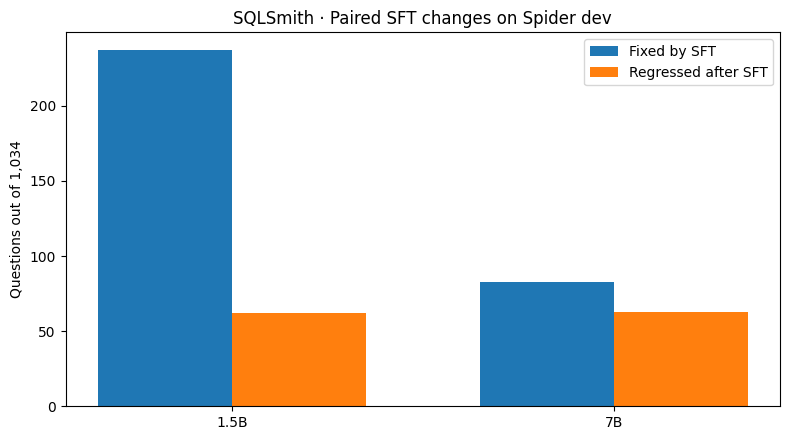

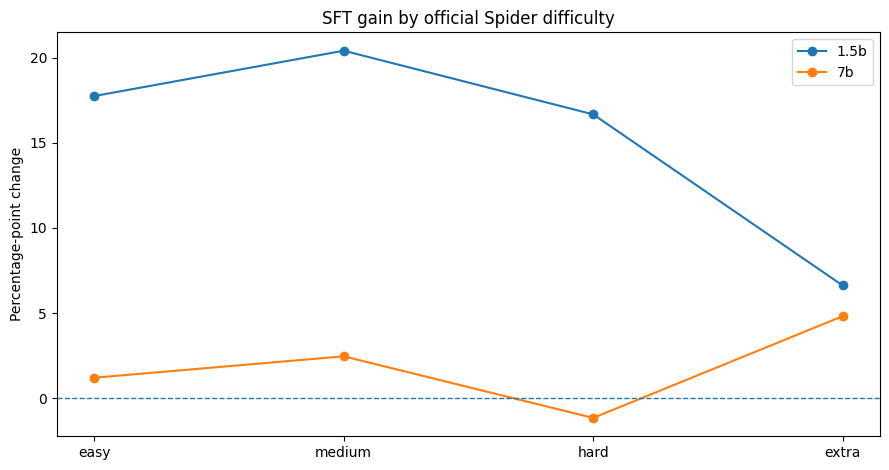

In [14]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(8,4.5))
labels=['1.5B','7B'];fixed=paired_df.fixed_by_sft.tolist();reg=paired_df.regressed_after_sft.tolist()
x=np.arange(2);w=.35
ax.bar(x-w/2,fixed,w,label='Fixed by SFT')
ax.bar(x+w/2,reg,w,label='Regressed after SFT')
ax.set_xticks(x,labels);ax.set_ylabel('Questions out of 1,034')
ax.set_title('SQLSmith · Paired SFT changes on Spider dev')
ax.legend();fig.tight_layout()
plt.savefig(OUT/'11_paired_changes.png',dpi=180)
plt.show()
fig,ax=plt.subplots(figsize=(9,4.8))
for m in ('1.5b','7b'):
    data=diff_df[diff_df.model==m].set_index('difficulty')
    order=[x for x in ['easy','medium','hard','extra'] if x in data.index]
    ax.plot(order,data.loc[order,'delta_pp'],marker='o',label=m)
ax.axhline(0,linewidth=1,linestyle='--')
ax.set_title('SFT gain by official Spider difficulty')
ax.set_ylabel('Percentage-point change');ax.legend();fig.tight_layout()
plt.savefig(OUT/'11_gain_by_difficulty.png',dpi=180)
plt.show()

## 13 — Generate the Milestone C research memo, provenance manifest, and final gate
Recommendations are framed as **hypotheses to test**, not invented error causes. Deliverables include the exact questions and both model predictions for manual study.

In [15]:
summary={
    'project':'SQLSmith', 'notebook':'11_SFT_Error_Analysis',
    'scope':'Spider 1.0 development set, 1034 questions in 20 databases',
    'official_test_suite_commit':EVALUATOR_COMMIT,
    'evaluation_flags':{'etype':'exec','plug_value':False,'keep_distinct':False},
    'baseline_and_sft_reconciliation':recon_df.to_dict(orient='records'),
    'paired_changes':paired_df.to_dict(orient='records'),
    'input_sha256':input_signature,
    'spider_dev_sha256':sha256_file(DEV),
    'test_suite_zip_sha256':sha256_file(ZIP),
    'generated_utc':datetime.now(timezone.utc).isoformat(),
    'notes':['Question-level official evaluator re-scoring, NOT string equivalence.',
             'SQLite compile diagnostics are heuristic and secondary.',
             'Development-set analysis is exploratory; do not claim independent test accuracy.'],
}
(OUT/'11_error_analysis_manifest.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
lines=['# SQLSmith — Milestone C / Notebook 11: Error Analysis','',
       '**Data:** 1,034 Spider dev examples, 20 databases; official augmented test-suite evaluator pinned to '+EVALUATOR_COMMIT+'.',
       '', '## Reconciliation to Notebook 10', '',
       '| Model | Variant | Correct / Total | Accuracy |', '|---|---|---:|---:|']
for _,r in recon_df.iterrows():
    lines.append(f"| {r['model']} | {r['variant']} | {r['correct']}/{r['total']} | {r['recomputed']:.2%} |")
lines += ['', '## Paired SFT changes', '',
          '| Model | Fixed | Regressed | Net gain | Δpp | Exploratory McNemar p |',
          '|---|---:|---:|---:|---:|---:|']
for _,r in paired_df.iterrows():
    lines.append(f"| {r['model']} | {int(r['fixed_by_sft'])} | {int(r['regressed_after_sft'])} | {int(r['net_correct_gain'])} | {r['delta_pp_unrounded']:+.2f} | {r['exact_mcnemar_p_exploratory']:.4g} |")
lines += ['', '## Worst five database changes by model', '',
          '| Model | Database | N | Δpp | Fixed | Regressed |','|---|---|---:|---:|---:|---:|']
for _,r in db_df.groupby('model').head(5).iterrows():
    lines.append(f"| {r['model']} | {r['db_id']} | {int(r['n'])} | {r['delta_pp']:+.1f} | {int(r['fixed'])} | {int(r['regressed'])} |")
lines += ['', '## Next experiments (hypotheses; not yet tested)', '',
          '1. Manually review the high-priority `11_manual_review_queue.csv` before assigning root-cause labels.',
          '2. Test schema/column grounding improvements on an internal development partition or alternate held-out tasks, then freeze the rules.',
          '3. Add a read-only SQL syntax/schema validator and measure both rejection rate and execution accuracy.',
          '4. Test feedback-based correction only for verifiable failures, with a fixed repair budget and measured latency.',
          '5. Evaluate final selected changes on genuinely unseen databases/datasets, not only this repeatedly analyzed Spider dev.',
          '', '## Limitations', '',
          '- Exact correctness is derived from the pinned augmented evaluator, not SQL-string equality.',
          '- Feature tags overlap and compile diagnoses are heuristic; associations do not establish failure causes.',
          '- McNemar and 20-database cluster-bootstrap intervals are exploratory on this reused development benchmark.',
          '- No inference, training or model weights are modified by Notebook 11.',
          '', '## Output location', '',f'`{OUT}`','']
MEMO=OUT/'11_milestone_C_error_analysis.md'
MEMO.write_text('\n'.join(lines),encoding='utf-8')
expected_outputs=[
 '11_score_reconciliation.csv','11_paired_change_summary.csv','11_by_official_difficulty.csv',
 '11_by_database.csv','11_gold_sql_feature_breakdown.csv','11_failure_triage.csv',
 '11_manual_review_queue.csv','11_all_questions_paired.csv','11_paired_changes.png',
 '11_gain_by_difficulty.png','11_error_analysis_manifest.json',MEMO.name]
assert all((OUT/name).is_file() for name in expected_outputs)
assert len(Q)==1034 and len(recon_df)==4 and len(paired_df)==2
print('PASS: Notebook 11 complete — 4 per-question official evaluations reconciled.')
print('Summary:');display(paired_df)
print('Report:',MEMO)
print('Directory:',OUT)
print('Suggested commit: feat: add official paired SFT error analysis for Milestone C')

PASS: Notebook 11 complete — 4 per-question official evaluations reconciled.
Summary:


,model,fixed_by_sft,regressed_after_sft,net_correct_gain,delta_pp_unrounded,exact_mcnemar_p_exploratory,cluster_bootstrap_95_low_pp,cluster_bootstrap_95_high_pp
0,1.5b,237,62,175,16.924565,2.881787e-25,12.489541,22.289918
1,7b,83,63,20,1.934236,1.155397e-01,-0.890911,4.940860


Report: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/milestone_C/error_analysis/11_milestone_C_error_analysis.md
Directory: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/milestone_C/error_analysis
Suggested commit: feat: add official paired SFT error analysis for Milestone C
